# Agente de análisis deportivo con IA

## Pregunta de negocio (Ask)
¿Qué factores históricos se asocian con el resultado de un partido de la Premier League y cómo podemos convertir esos hallazgos en recomendaciones, visualizaciones y respuestas conversacionales?

**Fuente principal:** OpenFootball `football.json`  
**Cobertura inicial:** Premier League, temporadas 2022-2023 a 2024-2025  
**Licencia de la fuente:** CC0 / dominio público

In [1]:
%pip install pandas polars duckdb pydantic requests pyarrow matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import requests
import seaborn as sns

In [2]:
from pydantic import BaseModel, Field, ValidationError

In [3]:
sns.set_theme(style="whitegrid", palette="deep")

RUTA_DATOS = Path("datos")
RUTA_DATOS.mkdir(exist_ok=True)

TEMPORADAS = ["2022-23", "2023-24", "2024-25"]
LIGA = "en.1"  # English Premier League

In [4]:
URL_BASE = (
    "https://raw.githubusercontent.com/openfootball/"
    "football.json/master"
)

datos_crudos = {}

for temporada in TEMPORADAS:
    url = f"{URL_BASE}/{temporada}/{LIGA}.json"
    respuesta = requests.get(url, timeout=30)
    respuesta.raise_for_status()

    datos_crudos[temporada] = respuesta.json()

    archivo_salida = RUTA_DATOS / f"premier_league_{temporada}.json"
    archivo_salida.write_text(
        json.dumps(datos_crudos[temporada], ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

print(f"Temporadas descargadas: {list(datos_crudos.keys())}")
print(f"Archivos guardados en: {RUTA_DATOS.resolve()}")

Temporadas descargadas: ['2022-23', '2023-24', '2024-25']
Archivos guardados en: C:\Users\ricar\ADML26\u5\datos


In [5]:
muestra = datos_crudos["2024-25"]

print("Nombre de la competencia:", muestra["name"])
print("Cantidad de partidos:", len(muestra["matches"]))
print("\nPrimer partido:")
muestra["matches"][0]

Nombre de la competencia: English Premier League 2024/25
Cantidad de partidos: 380

Primer partido:


{'round': 'Matchday 1',
 'date': '2024-08-16',
 'time': '20:00',
 'team1': 'Manchester United FC',
 'team2': 'Fulham FC',
 'score': {'ht': [0, 0], 'ft': [1, 0]}}

# PROCESS

In [6]:
from typing import Optional

class Marcador(BaseModel):
    ht: Optional[list[int]] = None
    ft: list[int] = Field(min_length=2, max_length=2)

class Partido(BaseModel):
    round: str
    date: str
    time: Optional[str] = None
    team1: str
    team2: str
    score: Marcador

In [7]:
partidos_validos = []
errores_validacion = []

for temporada, contenido in datos_crudos.items():
    for indice, partido_crudo in enumerate(contenido["matches"]):
        try:
            partido = Partido.model_validate(partido_crudo)
            partidos_validos.append({
                "temporada": temporada,
                **partido.model_dump()
            })
        except ValidationError as error:
            errores_validacion.append({
                "temporada": temporada,
                "indice": indice,
                "errores": error.errors()
            })

print(f"Partidos válidos: {len(partidos_validos)}")
print(f"Partidos con errores: {len(errores_validacion)}")

Partidos válidos: 1140
Partidos con errores: 0


In [8]:
registros_limpios = []

for partido in partidos_validos:
    goles_local, goles_visita = partido["score"]["ft"]

    if goles_local > goles_visita:
        resultado = "Local"
    elif goles_local < goles_visita:
        resultado = "Visita"
    else:
        resultado = "Empate"

    registros_limpios.append({
        "temporada": partido["temporada"],
        "jornada": partido["round"],
        "fecha": partido["date"],
        "hora": partido["time"],
        "equipo_local": partido["team1"],
        "equipo_visita": partido["team2"],
        "goles_local": goles_local,
        "goles_visita": goles_visita,
        "goles_totales": goles_local + goles_visita,
        "resultado": resultado
    })

df_partidos = pd.DataFrame(registros_limpios)

df_partidos["fecha"] = pd.to_datetime(df_partidos["fecha"])
df_partidos = df_partidos.sort_values(
    ["temporada", "fecha", "hora"]
).reset_index(drop=True)

df_partidos.to_csv(
    RUTA_DATOS / "premier_league_partidos_limpios.csv",
    index=False,
    encoding="utf-8"
)

print("Dimensiones:", df_partidos.shape)
df_partidos.head()

Dimensiones: (1140, 10)


,temporada,jornada,fecha,hora,equipo_local,equipo_visita,goles_local,goles_visita,goles_totales,resultado
0,2022-23,Matchday 1,2022-08-05,20:00,Crystal Palace FC,Arsenal FC,0,2,2,Visita
1,2022-23,Matchday 1,2022-08-06,12:30,Fulham FC,Liverpool FC,2,2,4,Empate
2,2022-23,Matchday 1,2022-08-06,15:00,Tottenham Hotspur FC,Southampton FC,4,1,5,Local
3,2022-23,Matchday 1,2022-08-06,15:00,Newcastle United FC,Nottingham Forest FC,2,0,2,Local
4,2022-23,Matchday 1,2022-08-06,15:00,Leeds United FC,Wolverhampton Wanderers FC,2,1,3,Local


In [9]:
print("Valores faltantes por columna:")
display(df_partidos.isna().sum())

print("\nDistribución de resultados:")
display(
    df_partidos["resultado"]
    .value_counts()
    .rename_axis("resultado")
    .reset_index(name="partidos")
)

Valores faltantes por columna:


temporada        0
jornada          0
fecha            0
hora             0
equipo_local     0
equipo_visita    0
goles_local      0
goles_visita     0
goles_totales    0
resultado        0
dtype: int64


Distribución de resultados:


,resultado,partidos
0,Local,514
1,Visita,364
2,Empate,262


In [10]:
df_partidos_polars = pl.from_pandas(df_partidos)

resumen_temporadas = (
    df_partidos_polars
    .group_by("temporada")
    .agg([
        pl.len().alias("partidos"),
        pl.col("goles_local").sum().alias("goles_locales"),
        pl.col("goles_visita").sum().alias("goles_visitantes"),
        pl.col("goles_totales").mean().round(2).alias("promedio_goles")
    ])
    .sort("temporada")
)

print("Dimensiones en Polars:", df_partidos_polars.shape)
resumen_temporadas

Dimensiones en Polars: (1140, 10)


temporada,partidos,goles_locales,goles_visitantes,promedio_goles
str,u32,i64,i64,f64
"""2022-23""",380,621,463,2.85
"""2023-24""",380,684,562,3.28
"""2024-25""",380,575,540,2.93


# DuckDB

In [11]:
RUTA_BD = RUTA_DATOS / "analisis_deportivo.duckdb"

conexion = duckdb.connect(str(RUTA_BD))

conexion.register("partidos_df", df_partidos)

conexion.execute("""
    CREATE OR REPLACE TABLE partidos AS
    SELECT * FROM partidos_df
""")

print("Base de datos creada en:", RUTA_BD.resolve())

conexion.execute("DESCRIBE partidos").df()

Base de datos creada en: C:\Users\ricar\ADML26\u5\datos\analisis_deportivo.duckdb


,column_name,column_type,null,key,default,extra
0,temporada,VARCHAR,YES,None,None,None
1,jornada,VARCHAR,YES,None,None,None
2,fecha,TIMESTAMP,YES,None,None,None
3,hora,VARCHAR,YES,None,None,None
4,equipo_local,VARCHAR,YES,None,None,None
5,equipo_visita,VARCHAR,YES,None,None,None
6,goles_local,BIGINT,YES,None,None,None
7,goles_visita,BIGINT,YES,None,None,None
8,goles_totales,BIGINT,YES,None,None,None
9,resultado,VARCHAR,YES,None,None,None


# Consulta SQL: desempeño por equipo y temporada

In [12]:
consulta_equipos = conexion.execute("""
    WITH participaciones AS (
        SELECT
            temporada,
            equipo_local AS equipo,
            goles_local AS goles_favor,
            goles_visita AS goles_contra,
            CASE
                WHEN resultado = 'Local' THEN 3
                WHEN resultado = 'Empate' THEN 1
                ELSE 0
            END AS puntos
        FROM partidos

        UNION ALL

        SELECT
            temporada,
            equipo_visita AS equipo,
            goles_visita AS goles_favor,
            goles_local AS goles_contra,
            CASE
                WHEN resultado = 'Visita' THEN 3
                WHEN resultado = 'Empate' THEN 1
                ELSE 0
            END AS puntos
        FROM partidos
    )

    SELECT
        temporada,
        equipo,
        COUNT(*) AS partidos_jugados,
        SUM(goles_favor) AS goles_favor,
        SUM(goles_contra) AS goles_contra,
        SUM(goles_favor) - SUM(goles_contra) AS diferencia_goles,
        SUM(puntos) AS puntos
    FROM participaciones
    GROUP BY temporada, equipo
    ORDER BY temporada, puntos DESC, diferencia_goles DESC
""").df()

consulta_equipos.head(10)

,temporada,equipo,partidos_jugados,goles_favor,goles_contra,diferencia_goles,puntos
0,2022-23,Manchester City FC,38,94.0,33.0,61.0,89.0
1,2022-23,Arsenal FC,38,88.0,43.0,45.0,84.0
2,2022-23,Manchester United FC,38,58.0,43.0,15.0,75.0
3,2022-23,Newcastle United FC,38,68.0,33.0,35.0,71.0
4,2022-23,Liverpool FC,38,75.0,47.0,28.0,67.0
5,2022-23,Brighton & Hove Albion FC,38,72.0,53.0,19.0,62.0
6,2022-23,Aston Villa FC,38,51.0,46.0,5.0,61.0
7,2022-23,Tottenham Hotspur FC,38,70.0,63.0,7.0,60.0
8,2022-23,Brentford FC,38,58.0,46.0,12.0,59.0
9,2022-23,Fulham FC,38,55.0,53.0,2.0,52.0


# Visualización de goles y resultados

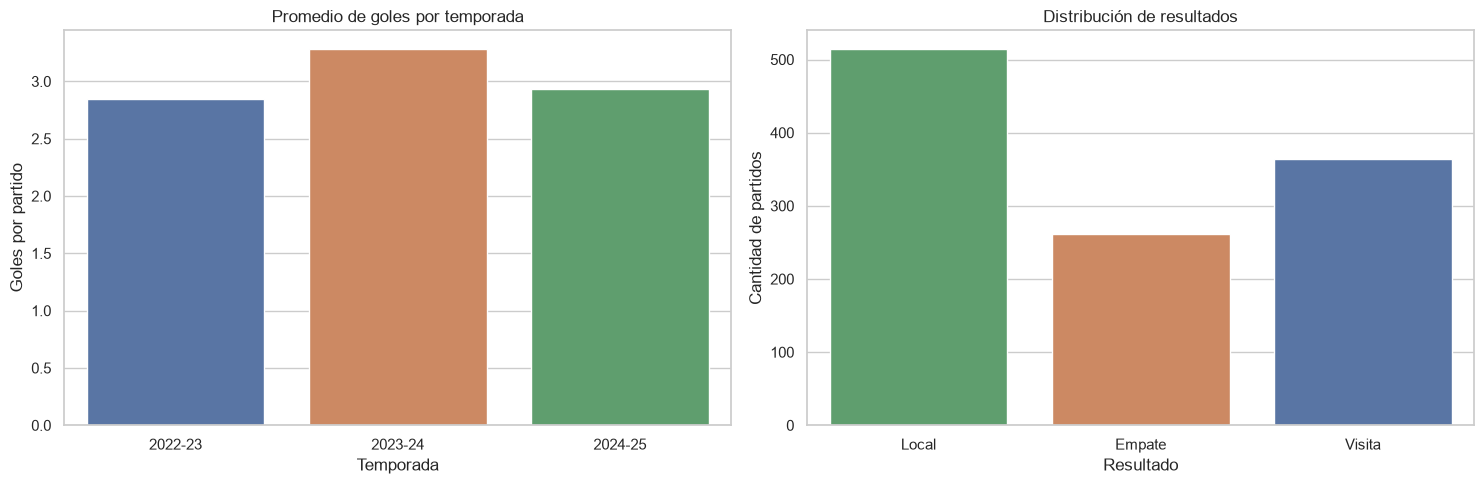

In [13]:
resumen_pandas = resumen_temporadas.to_pandas()

orden_resultados = ["Local", "Empate", "Visita"]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=resumen_pandas,
    x="temporada",
    y="promedio_goles",
    hue="temporada",
    legend=False,
    ax=ejes[0]
)
ejes[0].set_title("Promedio de goles por temporada")
ejes[0].set_xlabel("Temporada")
ejes[0].set_ylabel("Goles por partido")

sns.countplot(
    data=df_partidos,
    x="resultado",
    order=orden_resultados,
    hue="resultado",
    legend=False,
    ax=ejes[1]
)
ejes[1].set_title("Distribución de resultados")
ejes[1].set_xlabel("Resultado")
ejes[1].set_ylabel("Cantidad de partidos")

plt.tight_layout()
plt.show()

# Variables historicas para predicción

In [14]:
from collections import defaultdict, deque

In [15]:
def crear_dataset_modelo(datos):
    registros = []

    datos_ordenados = datos.sort_values(
        ["temporada", "fecha", "hora"]
    ).copy()

    for temporada, partidos_temporada in datos_ordenados.groupby("temporada"):
        historial = defaultdict(lambda: deque(maxlen=5))

        for _, partido in partidos_temporada.iterrows():
            local = partido["equipo_local"]
            visita = partido["equipo_visita"]

            historial_local = list(historial[local])
            historial_visita = list(historial[visita])

            def promedio(historial_equipo, columna):
                if not historial_equipo:
                    return 0.0
                return sum(x[columna] for x in historial_equipo) / len(historial_equipo)

            registros.append({
                "temporada": temporada,
                "fecha": partido["fecha"],
                "equipo_local": local,
                "equipo_visita": visita,
                "partidos_previos_local": len(historial_local),
                "partidos_previos_visita": len(historial_visita),
                "puntos_promedio_local": promedio(historial_local, "puntos"),
                "puntos_promedio_visita": promedio(historial_visita, "puntos"),
                "goles_favor_promedio_local": promedio(historial_local, "goles_favor"),
                "goles_favor_promedio_visita": promedio(historial_visita, "goles_favor"),
                "goles_contra_promedio_local": promedio(historial_local, "goles_contra"),
                "goles_contra_promedio_visita": promedio(historial_visita, "goles_contra"),
                "resultado": partido["resultado"]
            })

            if partido["resultado"] == "Local":
                puntos_local, puntos_visita = 3, 0
            elif partido["resultado"] == "Visita":
                puntos_local, puntos_visita = 0, 3
            else:
                puntos_local, puntos_visita = 1, 1

            historial[local].append({
                "puntos": puntos_local,
                "goles_favor": partido["goles_local"],
                "goles_contra": partido["goles_visita"]
            })

            historial[visita].append({
                "puntos": puntos_visita,
                "goles_favor": partido["goles_visita"],
                "goles_contra": partido["goles_local"]
            })

    return pd.DataFrame(registros)


df_modelo = crear_dataset_modelo(df_partidos)

df_modelo = df_modelo[
    (df_modelo["partidos_previos_local"] >= 3) &
    (df_modelo["partidos_previos_visita"] >= 3)
].reset_index(drop=True)

print("Partidos disponibles para modelado:", len(df_modelo))
df_modelo.head()

Partidos disponibles para modelado: 1049


,temporada,fecha,equipo_local,equipo_visita,partidos_previos_local,partidos_previos_visita,puntos_promedio_local,puntos_promedio_visita,goles_favor_promedio_local,goles_favor_promedio_visita,goles_contra_promedio_local,goles_contra_promedio_visita,resultado
0,2022-23,2022-08-27,Southampton FC,Manchester United FC,3,3,1.333333,1.000000,1.666667,1.000000,2.333333,2.333333,Visita
1,2022-23,2022-08-27,Manchester City FC,Crystal Palace FC,3,3,2.333333,1.333333,3.000000,1.333333,1.000000,1.333333,Local
2,2022-23,2022-08-27,Liverpool FC,AFC Bournemouth,3,3,0.666667,1.000000,1.333333,0.666667,1.666667,2.333333,Local
3,2022-23,2022-08-27,Chelsea FC,Leicester City FC,3,3,1.333333,0.333333,1.000000,1.666667,1.666667,2.666667,Local
4,2022-23,2022-08-27,Brighton & Hove Albion FC,Leeds United FC,3,3,2.333333,2.333333,1.333333,2.333333,0.333333,1.000000,Local


# Entrenamiento y prueba

In [16]:
variables_modelo = [
    "puntos_promedio_local",
    "puntos_promedio_visita",
    "goles_favor_promedio_local",
    "goles_favor_promedio_visita",
    "goles_contra_promedio_local",
    "goles_contra_promedio_visita"
]

entrenamiento = df_modelo[
    df_modelo["temporada"].isin(["2022-23", "2023-24"])
].copy()

prueba = df_modelo[
    df_modelo["temporada"] == "2024-25"
].copy()

X_entrenamiento = entrenamiento[variables_modelo]
y_entrenamiento = entrenamiento["resultado"]

X_prueba = prueba[variables_modelo]
y_prueba = prueba["resultado"]

print("Partidos de entrenamiento:", len(X_entrenamiento))
print("Partidos de prueba:", len(X_prueba))

Partidos de entrenamiento: 699
Partidos de prueba: 350


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [18]:
modelo_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

modelo_rf.fit(X_entrenamiento, y_entrenamiento)

predicciones = modelo_rf.predict(X_prueba)

exactitud = accuracy_score(y_prueba, predicciones)

print(f"Exactitud del modelo: {exactitud:.2%}")
print("\nReporte de clasificación:")
print(classification_report(y_prueba, predicciones))

matriz = confusion_matrix(
    y_prueba,
    predicciones,
    labels=["Local", "Empate", "Visita"]
)

matriz_df = pd.DataFrame(
    matriz,
    index=["Real: Local", "Real: Empate", "Real: Visita"],
    columns=["Predicho: Local", "Predicho: Empate", "Predicho: Visita"]
)

matriz_df

Exactitud del modelo: 44.57%

Reporte de clasificación:
              precision    recall  f1-score   support

      Empate       0.26      0.16      0.20        86
       Local       0.48      0.54      0.51       144
      Visita       0.47      0.53      0.50       120

    accuracy                           0.45       350
   macro avg       0.41      0.41      0.40       350
weighted avg       0.43      0.45      0.43       350



,Predicho: Local,Predicho: Empate,Predicho: Visita
Real: Local,78,24,42
Real: Empate,42,14,30
Real: Visita,41,15,64


In [19]:
%pip install "flaml[automl]"

Note: you may need to restart the kernel to use updated packages.


# AutoML

In [25]:
from flaml import AutoML

In [26]:
automl = AutoML()

automl.fit(
    X_train=X_entrenamiento,
    y_train=y_entrenamiento,
    task="classification",
    metric="accuracy",
    time_budget=30,
    estimator_list=["rf", "extra_tree"],
    n_jobs=-1,
    log_file_name="",
    verbose=0
)

predicciones_automl = automl.predict(X_prueba)
exactitud_automl = accuracy_score(y_prueba, predicciones_automl)

print("Mejor modelo elegido por AutoML:", automl.model.estimator)
print(f"Exactitud AutoML: {exactitud_automl:.2%}")
print(f"Exactitud Random Forest manual: {exactitud:.2%}")
print("\nMejor configuración encontrada:")
print(automl.best_config)

Mejor modelo elegido por AutoML: RandomForestClassifier(criterion='entropy',
                       max_features=np.float64(0.4883292491335932),
                       max_leaf_nodes=5, n_estimators=11, n_jobs=-1,
                       random_state=12032022)
Exactitud AutoML: 44.86%
Exactitud Random Forest manual: 44.57%

Mejor configuración encontrada:
{'n_estimators': 11, 'max_features': np.float64(0.4883292491335932), 'max_leaves': 5, 'criterion': 'entropy'}


In [27]:
# PCA y K-Means

In [28]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [29]:
variables_cluster = [
    "goles_favor",
    "goles_contra",
    "diferencia_goles",
    "puntos"
]

datos_cluster = consulta_equipos[
    ["temporada", "equipo"] + variables_cluster
].dropna().copy()

escalador = StandardScaler()
datos_escalados = escalador.fit_transform(
    datos_cluster[variables_cluster]
)

pca = PCA(n_components=2)
componentes_pca = pca.fit_transform(datos_escalados)

kmeans = KMeans(
    n_clusters=3,
    n_init=20,
    random_state=42
)

datos_cluster["cluster"] = kmeans.fit_predict(datos_escalados)
datos_cluster["componente_1"] = componentes_pca[:, 0]
datos_cluster["componente_2"] = componentes_pca[:, 1]

varianza_explicada = pca.explained_variance_ratio_.sum()

print(f"Varianza explicada por PCA: {varianza_explicada:.2%}")
datos_cluster.head()

Varianza explicada por PCA: 98.77%


C:\Users\ricar\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,temporada,equipo,goles_favor,goles_contra,diferencia_goles,puntos,cluster,componente_1,componente_2
0,2022-23,Manchester City FC,94.0,33.0,61.0,89.0,2,3.972020,0.323165
1,2022-23,Arsenal FC,88.0,43.0,45.0,84.0,2,3.044969,0.564315
2,2022-23,Manchester United FC,58.0,43.0,15.0,75.0,2,1.385355,-0.667054
3,2022-23,Newcastle United FC,68.0,33.0,35.0,71.0,2,2.246397,-0.750812
4,2022-23,Liverpool FC,75.0,47.0,28.0,67.0,2,1.754832,0.217820


In [30]:
## Visualizacion de los grupos de equipos

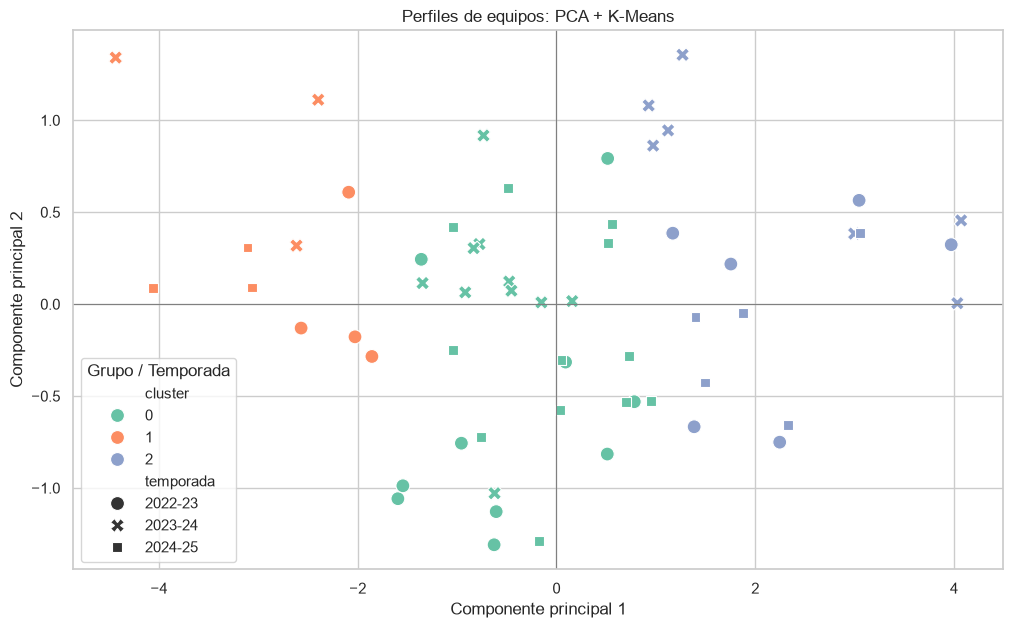

In [31]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=datos_cluster,
    x="componente_1",
    y="componente_2",
    hue="cluster",
    style="temporada",
    palette="Set2",
    s=100
)

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)

plt.title("Perfiles de equipos: PCA + K-Means")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Grupo / Temporada")
plt.show()

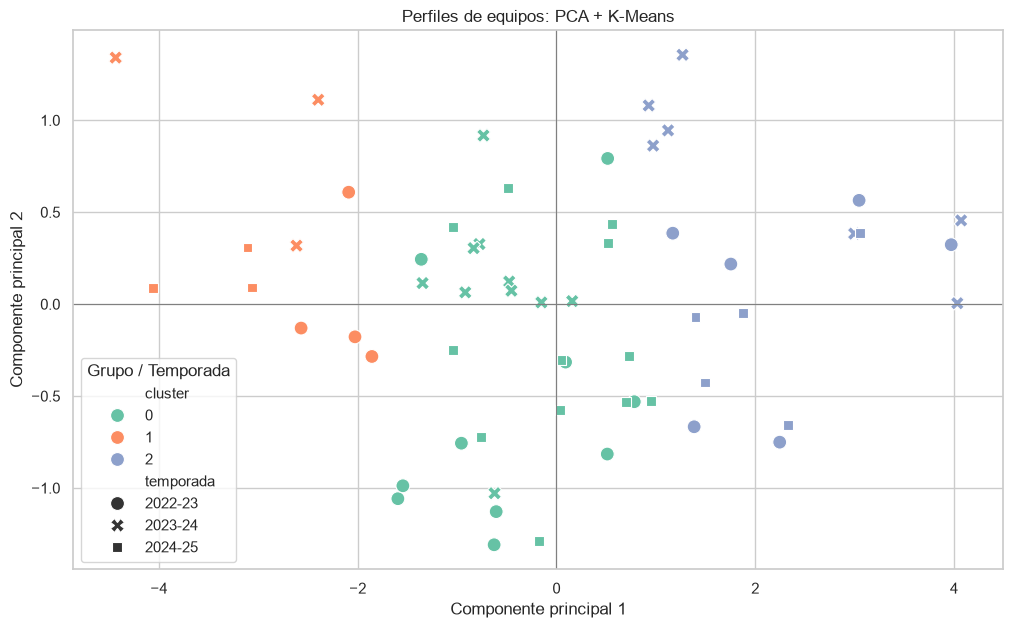

In [32]:
# interpretar cada grupo
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=datos_cluster,
    x="componente_1",
    y="componente_2",
    hue="cluster",
    style="temporada",
    palette="Set2",
    s=100
)

plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)

plt.title("Perfiles de equipos: PCA + K-Means")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Grupo / Temporada")
plt.show()

In [33]:
# RAG

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [35]:
documentos_rag = []

for _, fila in consulta_equipos.iterrows():
    texto = (
        f"En la temporada {fila['temporada']}, "
        f"{fila['equipo']} jugó {fila['partidos_jugados']} partidos, "
        f"obtuvo {fila['puntos']} puntos, anotó {fila['goles_favor']} goles, "
        f"recibió {fila['goles_contra']} goles y tuvo una diferencia de goles "
        f"de {fila['diferencia_goles']}."
    )

    documentos_rag.append({
        "texto": texto,
        "temporada": fila["temporada"],
        "equipo": fila["equipo"],
        "puntos": fila["puntos"]
    })

textos_rag = [documento["texto"] for documento in documentos_rag]

vectorizador = TfidfVectorizer()
matriz_rag = vectorizador.fit_transform(textos_rag)

print(f"Documentos disponibles para RAG: {len(documentos_rag)}")
print(textos_rag[0])

Documentos disponibles para RAG: 60
En la temporada 2022-23, Manchester City FC jugó 38 partidos, obtuvo 89.0 puntos, anotó 94.0 goles, recibió 33.0 goles y tuvo una diferencia de goles de 61.0.


In [36]:
def recuperar_contexto(pregunta, cantidad=3):
    vector_pregunta = vectorizador.transform([pregunta])
    similitudes = cosine_similarity(vector_pregunta, matriz_rag).flatten()

    mejores_indices = similitudes.argsort()[-cantidad:][::-1]

    return [
        {
            "similitud": round(float(similitudes[indice]), 3),
            **documentos_rag[indice]
        }
        for indice in mejores_indices
    ]


pregunta = "¿Qué equipos obtuvieron más puntos en la temporada 2023-24?"
contexto = recuperar_contexto(pregunta)

for resultado in contexto:
    print(
        f"Similitud: {resultado['similitud']} | "
        f"{resultado['texto']}"
    )

Similitud: 0.452 | En la temporada 2023-24, Burnley FC jugó 38 partidos, obtuvo 24.0 puntos, anotó 41.0 goles, recibió 78.0 goles y tuvo una diferencia de goles de -37.0.
Similitud: 0.389 | En la temporada 2023-24, Fulham FC jugó 38 partidos, obtuvo 47.0 puntos, anotó 55.0 goles, recibió 61.0 goles y tuvo una diferencia de goles de -6.0.
Similitud: 0.386 | En la temporada 2023-24, Manchester United FC jugó 38 partidos, obtuvo 60.0 puntos, anotó 57.0 goles, recibió 58.0 goles y tuvo una diferencia de goles de -1.0.


In [37]:
# Agente conversacional con memoria y herramientas

In [38]:
import re

In [39]:
memoria_conversacion = []

def agente_deportivo(pregunta):
    pregunta_normalizada = pregunta.lower()
    coincidencia_temporada = re.search(r"\b20\d{2}-\d{2}\b", pregunta)

    temporada = (
        coincidencia_temporada.group()
        if coincidencia_temporada
        else None
    )

    if "más puntos" in pregunta_normalizada:
        if temporada:
            consulta = """
                SELECT temporada, equipo, puntos, goles_favor,
                       goles_contra, diferencia_goles
                FROM consulta_equipos
                WHERE temporada = ?
                ORDER BY puntos DESC, diferencia_goles DESC
                LIMIT 1
            """
            resultado = conexion.execute(
                consulta, [temporada]
            ).df()
        else:
            consulta = """
                SELECT temporada, equipo, puntos, goles_favor,
                       goles_contra, diferencia_goles
                FROM consulta_equipos
                ORDER BY puntos DESC, diferencia_goles DESC
                LIMIT 1
            """
            resultado = conexion.execute(consulta).df()

        fila = resultado.iloc[0]

        respuesta = (
            f"El equipo con más puntos en la temporada "
            f"{fila['temporada']} fue {fila['equipo']}, "
            f"con {int(fila['puntos'])} puntos y una diferencia "
            f"de goles de {int(fila['diferencia_goles'])}."
        )
        herramienta_usada = "DuckDB"

    else:
        contexto = recuperar_contexto(pregunta, cantidad=2)

        respuesta = (
            "No identifiqué una consulta estadística exacta. "
            "Estos son los documentos más relevantes:\n\n"
            + "\n".join(f"- {item['texto']}" for item in contexto)
        )
        herramienta_usada = "RAG con TF-IDF"

    memoria_conversacion.append({
        "pregunta": pregunta,
        "respuesta": respuesta,
        "herramienta": herramienta_usada
    })

    return respuesta, herramienta_usada

In [40]:
pregunta = "¿Qué equipo obtuvo más puntos en la temporada 2023-24?"

respuesta, herramienta = agente_deportivo(pregunta)

print("Pregunta:", pregunta)
print("Herramienta utilizada:", herramienta)
print("Respuesta:", respuesta)

Pregunta: ¿Qué equipo obtuvo más puntos en la temporada 2023-24?
Herramienta utilizada: DuckDB
Respuesta: El equipo con más puntos en la temporada 2023-24 fue Manchester City FC, con 91 puntos y una diferencia de goles de 62.


In [41]:
# Dashboard desde lenguaje natural

In [42]:
def generar_dashboard(peticion):
    texto = peticion.lower()

    if "goles" in texto and "temporada" in texto:
        datos_grafica = resumen_temporadas.to_pandas()

        plt.figure(figsize=(9, 5))
        sns.barplot(
            data=datos_grafica,
            x="temporada",
            y="promedio_goles",
            hue="temporada",
            legend=False
        )
        plt.title("Dashboard: promedio de goles por temporada")
        plt.xlabel("Temporada")
        plt.ylabel("Promedio de goles por partido")
        plt.show()

        return "Dashboard generado: promedio de goles por temporada."

    if "resultado" in texto or "local" in texto:
        plt.figure(figsize=(8, 5))
        sns.countplot(
            data=df_partidos,
            x="resultado",
            order=["Local", "Empate", "Visita"],
            hue="resultado",
            legend=False
        )
        plt.title("Dashboard: distribución de resultados")
        plt.xlabel("Resultado")
        plt.ylabel("Cantidad de partidos")
        plt.show()

        return "Dashboard generado: distribución de resultados."

    return (
        "No reconocí la solicitud. Prueba con: "
        "'muestra goles por temporada' o 'muestra resultados locales'."
    )

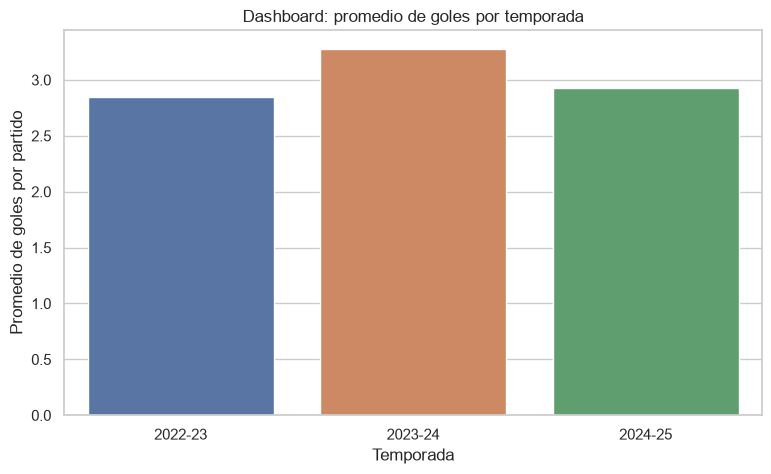

Dashboard generado: promedio de goles por temporada.


In [43]:
solicitud_dashboard = "Muestra el promedio de goles por temporada"

mensaje = generar_dashboard(solicitud_dashboard)

print(mensaje)